# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024160074
NAME = "Muskan"

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160074   Name: Muskan   Fingerprint: 823DBE6C   Tickets: 16

Ticket_ID                                                                                   Ticket_Text
      T01                                                         The Wi-Fi works, but the VPN doesn't.
      T02 Student portal has stopped syncing before the assignment deadline. I don't know what changed.
      T03                  I can't open the laptop before the assignment deadline. It worked yesterday.
      T04                          Projector is not working on my laptop. It works on another computer.
      T05                                                                Error code 0x80070005 appears.
      T06                    Python has stopped syncing since yesterday. The same problem occurs again.
      T07                                      The Matlab is running slowly. I don't know what changed.
      T08                                   Lms keeps disconnecting during the lab. Can yo

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:

results = []
for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])
    results.append(result)

rows = []
for i, result in enumerate(results):
    rows.append({
        "Ticket_ID": df.iloc[i]["Ticket_ID"],
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique tokens": len(set(result["tokens"])),
        "Final tokens": len(result["final"])
    })

q1_table = pd.DataFrame(rows)

total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": q1_table["Sentences"].sum(),
    "Tokens": q1_table["Tokens"].sum(),
    "Punctuation tokens": q1_table["Punctuation tokens"].sum(),
    "Stopwords": q1_table["Stopwords"].sum(),
    "Unique tokens": len(set(
        token
        for result in results
        for token in result["tokens"]
    )),
    "Final tokens": q1_table["Final tokens"].sum()
}

q1_table = pd.concat(
    [q1_table, pd.DataFrame([total_row])],
    ignore_index=True
)

display(q1_table)

# Display the actual processing output for the two focus tickets
print("Focus ticket IDs:", FOCUS)

for ticket_id in FOCUS:
    idx = df.index[df["Ticket_ID"] == ticket_id][0]
    print("\nTicket ID:", ticket_id)
    print("Raw text:", df.loc[idx, "Ticket_Text"])
    print("Sentences:", results[idx]["sentences"])
    print("Tokens:", results[idx]["tokens"])
    print("Punctuation:", results[idx]["punct"])
    print("Stopwords:", results[idx]["stops"])
    print("Final tokens:", results[idx]["final"])


,Ticket_ID,Sentences,Tokens,Punctuation tokens,Stopwords,Unique tokens,Final tokens
0,T01,1,10,2,4,9,4
1,T02,2,17,2,6,16,9
2,T03,2,15,2,5,13,8
3,T04,2,14,2,6,12,6
4,T05,1,5,1,0,5,4
5,T06,2,13,2,4,12,7
6,T07,2,13,2,5,12,6
7,T08,2,12,2,5,12,5
8,T09,2,16,2,6,15,8
9,T10,2,17,2,8,15,7


Focus ticket IDs: ['T02', 'T04']

Ticket ID: T02
Raw text: Student portal has stopped syncing before the assignment deadline. I don't know what changed.
Sentences: ['Student portal has stopped syncing before the assignment deadline.', "I don't know what changed."]
Tokens: ['student', 'portal', 'has', 'stopped', 'syncing', 'before', 'the', 'assignment', 'deadline', '.', 'i', 'do', "n't", 'know', 'what', 'changed', '.']
Punctuation: ['.', '.']
Stopwords: ['has', 'before', 'the', 'i', 'do', 'what']
Final tokens: ['student', 'portal', 'stopped', 'syncing', 'assignment', 'deadline', "n't", 'know', 'changed']

Ticket ID: T04
Raw text: Projector is not working on my laptop. It works on another computer.
Sentences: ['Projector is not working on my laptop.', 'It works on another computer.']
Tokens: ['projector', 'is', 'not', 'working', 'on', 'my', 'laptop', '.', 'it', 'works', 'on', 'another', 'computer', '.']
Punctuation: ['.', '.']
Stopwords: ['is', 'not', 'on', 'my', 'it', 'on']
Final tokens

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]


import re
from collections import Counter

long_word_pattern = r"\b[A-Za-z]{6,}\b"

# Keep decimals and versions such as 95.5 and 2.0.1 together.
number_pattern = r"(?<![\w.])\d+(?:\.\d+)+(?![\w.])|(?<![\w.])\d+(?:,\d{3})*(?![\w.])"

capitalized_pattern = r"\b[A-Z][a-zA-Z]*\b"
vowel_pattern = r"\b[AEIOUaeiou][a-zA-Z]*\b"

email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"

url_pattern = (
    r"https?://[^\s<>\"']+|www\.[^\s<>\"']+"
)

phone_pattern = (
    r"(?<!\w)(?:\+\d{1,3}[-.\s]?)?"
    r"(?:\(?\d{3,5}\)?[-.\s]?)\d{3,5}[-.\s]?\d{4}(?!\w)"
)

def redact_sensitive(text):
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text

def analyze_regex(label, text):
    print(f"\n{label}: {text}")
    print("Words longer than 5 letters:",
          re.findall(long_word_pattern, text))
    print("Numbers:",
          re.findall(number_pattern, text))
    print("Capitalized words:",
          re.findall(capitalized_pattern, text))
    print("Words beginning with vowels:",
          re.findall(vowel_pattern, text))
    print("Redacted text:", redact_sensitive(text))

print("========== TEST_LINES ==========")
for i, line in enumerate(TEST_LINES, start=1):
    analyze_regex(f"TEST_LINE {i}", line)

print("\n========== GENERATED TICKETS ==========")
for _, row in df.iterrows():
    analyze_regex(row["Ticket_ID"], row["Ticket_Text"])

# Estimate capitalized words occurring at sentence beginnings
sentence_initial_words = []
all_capitalized_words = []

for text in df["Ticket_Text"]:
    for sentence in sent_tokenize(text):
        matches = re.findall(capitalized_pattern, sentence)
        all_capitalized_words.extend(matches)

        first_word = re.match(r"\s*([A-Z][a-zA-Z]*)", sentence)
        if first_word:
            sentence_initial_words.append(first_word.group(1))

initial_counts = Counter(sentence_initial_words)
capitalized_counts = Counter(all_capitalized_words)

sentence_initial_only = sum(
    min(count, capitalized_counts[word])
    for word, count in initial_counts.items()
)

print("\nCapitalized-word occurrences:", len(all_capitalized_words))
print("Sentence-initial capitalized-word occurrences:",
      sentence_initial_only)
print("Sentence-initial words:", sentence_initial_words)


========== TEST_LINES ==========

TEST_LINE 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Words longer than 5 letters: ['helpdesk', 'thapar', 'thapar', 'thapar']
Numbers: []
Capitalized words: ['Mail']
Words beginning with vowels: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
Redacted text: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>

TEST_LINE 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Words longer than 5 letters: ['Version']
Numbers: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '2.0.1', '95.5', '1']
Capitalized words: ['Call', 'Version', 'Rs']
Words beginning with vowels: ['or', 'is']
Redacted text: Call +91 98765 43210, +91-98765-43210 or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

TEST_LINE 3: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Words longer than 5 letters: []
Numbers: [

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:


import re
from nltk.tokenize import RegexpTokenizer, word_tokenize

token_pattern = (
    r"https?://[^\s<>\"']+|www\.[^\s<>\"']+"
    r"|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"
    r"|(?<!\w)(?:\+\d{1,3}[-.\s]?)?"
    r"(?:\(?\d{3,5}\)?[-.\s]?)\d{3,5}[-.\s]?\d{4}(?!\w)"
    r"|\b\d+(?:\.\d+)+\b"
    r"|\b[A-Za-z]+(?:-[A-Za-z]+)+\b"
    r"|\b[A-Za-z]+(?:['’][A-Za-z]+)+\b"
    r"|\b[A-Za-z]+\b"
    r"|\d+(?:,\d{3})+"
    r"|\d+"
    r"|[^\w\s]"
)

custom_tokenizer = RegexpTokenizer(token_pattern)

def my_tokenize(text):
    return custom_tokenizer.tokenize(text)

print("========== TEST_LINES ==========")
for i, line in enumerate(TEST_LINES, start=1):
    print(f"\nTEST_LINE {i}: {line}")
    print("my_tokenize():", my_tokenize(line))
    print("word_tokenize():", word_tokenize(line))

print("\n========== GENERATED TICKETS ==========")
different_ticket_ids = []

for _, row in df.iterrows():
    custom_tokens = my_tokenize(row["Ticket_Text"])
    standard_tokens = word_tokenize(row["Ticket_Text"])

    print(f"\n{row['Ticket_ID']}: {row['Ticket_Text']}")
    print("my_tokenize():", custom_tokens)
    print("word_tokenize():", standard_tokens)

    if custom_tokens != standard_tokens:
        different_ticket_ids.append(row["Ticket_ID"])

print("\nTickets tokenized differently:",
      len(different_ticket_ids), "out of", len(df))
print("Ticket IDs:", different_ticket_ids)


========== TEST_LINES ==========

TEST_LINE 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize(): ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize(): ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

TEST_LINE 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize(): ['Call', '+', '91', '98765', '43210', ',', '+', '91', '-', '98765', '-', '43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
word_tokenize(): ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

TEST_

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:


import pandas as pd
from nltk.stem import PorterStemmer, LancasterStemmer
from nltk.stem import RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet

porter = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()

# RegexpStemmer removes common suffixes.
# We will inspect its results to identify possible over-stemming.
regexp_stemmer = RegexpStemmer(
    r"(ing|edly|ed|ly|es|s)$",
    min=4
)

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    elif tag.startswith("V"):
        return wordnet.VERB
    elif tag.startswith("N"):
        return wordnet.NOUN
    elif tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

# Obtain unique final tokens using the official pipeline.
q4_tokens = sorted({
    token
    for _, row in df.iterrows()
    for token in process_ticket(row["Ticket_Text"])["final"]
})

# POS-tag the tokens.
tagged_words = pos_tag(q4_tokens)

comparison = []

for word, tag in tagged_words:
    pos = get_wordnet_pos(tag)

    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regexp_result = regexp_stemmer.stem(word)
    lemma_result = lemmatizer.lemmatize(word, pos=pos)

    outputs = [
        porter_result,
        lancaster_result,
        regexp_result,
        lemma_result
    ]

    if len(set(outputs)) > 1:
        comparison.append({
            "Word": word,
            "POS tag": tag,
            "Porter Stem": porter_result,
            "Lancaster Stem": lancaster_result,
            "Regexp Stem": regexp_result,
            "WordNet Lemma": lemma_result
        })

q4_table = pd.DataFrame(comparison)

print("Number of unique final tokens:", len(q4_tokens))
print("Words with differing outputs:", len(q4_table))
display(q4_table)


Number of unique final tokens: 61
Words with differing outputs: 32


,Word,POS tag,Porter Stem,Lancaster Stem,Regexp Stem,WordNet Lemma
0,access,NN,access,access,acces,access
1,another,DT,anoth,anoth,another,another
2,assignment,NN,assign,assign,assignment,assignment
3,changed,VB,chang,chang,chang,change
4,closed,VBD,close,clos,clos,close
5,code,NN,code,cod,code,code
6,computer,NN,comput,comput,computer,computer
7,deadline,NN,deadlin,deadlin,deadline,deadline
8,error,NN,error,er,error,error
9,file,NN,file,fil,file,file


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total tokens,Unique tokens,TTR
0,S1 - All tokens,199,94,0.4724
1,S2 - No punctuation,167,87,0.5210
2,S3 - Final tokens,99,61,0.6162
3,S4 - Porter stemmed,99,59,0.5960



Top 10 words in S1:
[('.', 25), ('the', 17), ('i', 8), ("n't", 5), ('yesterday', 4), ('is', 4), ('has', 3), ('stopped', 3), ('syncing', 3), ('do', 3)]

Top 10 words in S3:
[("n't", 5), ('yesterday', 4), ('stopped', 3), ('syncing', 3), ('know', 3), ('changed', 3), ('tried', 3), ('works', 2), ('vpn', 2), ('assignment', 2)]


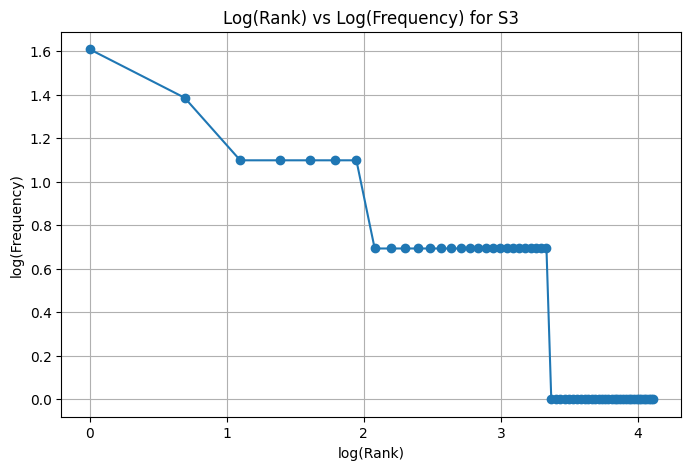


Top 5 bigrams in S1:
[(('.', 'i'), 8), (('.', 'the'), 5), (('yesterday', '.'), 4), (('has', 'stopped'), 3), (('stopped', 'syncing'), 3)]

Top 5 bigrams in S3:
[(('stopped', 'syncing'), 3), (("n't", 'know'), 3), (('know', 'changed'), 3), (('assignment', 'deadline'), 2), (('python', 'stopped'), 2)]


In [ ]:


import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from nltk.util import bigrams
from nltk.stem import PorterStemmer

porter = PorterStemmer()

# Process every ticket with the official pipeline.
processed = [
    process_ticket(text)
    for text in df["Ticket_Text"]
]

# S1: All lowercase tokens, including punctuation and stopwords.
S1 = [
    token
    for result in processed
    for token in result["tokens"]
]

# S2: All tokens except punctuation tokens.
S2 = [
    token
    for result in processed
    for token in result["tokens"]
    if token not in result["punct"]
]

# S3: Final tokens after punctuation and stopword removal.
S3 = [
    token
    for result in processed
    for token in result["final"]
]

# S4: Porter-stemmed version of S3.
S4 = [porter.stem(token) for token in S3]

def corpus_stats(name, tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total > 0 else 0

    return {
        "Corpus": name,
        "Total tokens": total,
        "Unique tokens": unique,
        "TTR": round(ttr, 4)
    }

stats = pd.DataFrame([
    corpus_stats("S1 - All tokens", S1),
    corpus_stats("S2 - No punctuation", S2),
    corpus_stats("S3 - Final tokens", S3),
    corpus_stats("S4 - Porter stemmed", S4)
])

display(stats)

print("\nTop 10 words in S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 words in S3:")
print(Counter(S3).most_common(10))

# Log(rank) versus log(frequency) for S3.
frequency_counts = sorted(
    Counter(S3).values(),
    reverse=True
)

if frequency_counts:
    ranks = list(range(1, len(frequency_counts) + 1))

    log_ranks = [math.log(rank) for rank in ranks]
    log_frequencies = [
        math.log(freq)
        for freq in frequency_counts
    ]

    plt.figure(figsize=(8, 5))
    plt.plot(log_ranks, log_frequencies, marker="o")
    plt.xlabel("log(Rank)")
    plt.ylabel("log(Frequency)")
    plt.title("Log(Rank) vs Log(Frequency) for S3")
    plt.grid(True)
    plt.show()
else:
    print("S3 is empty; cannot plot frequencies.")

print("\nTop 5 bigrams in S1:")
print(Counter(bigrams(S1)).most_common(5))

print("\nTop 5 bigrams in S3:")
print(Counter(bigrams(S3)).most_common(5))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*